# Baseline PM2.5 Bogotá — 3 fases de tratamiento de datos faltantes

Este cuaderno construye un **modelo baseline de Random Forest** para pronóstico de PM2.5 a 1 hora,
y lo evalúa bajo **tres estrategias distintas de tratamiento de datos faltantes**, manteniendo
**el mismo modelo, la misma ventana temporal y el mismo conjunto de test** en las tres — así
cualquier diferencia de desempeño se puede atribuir limpiamente a la estrategia de datos, no al modelo.

## Diseño experimental (resumen)

| Fase | Estrategia | Rol |
|---|---|---|
| 0 | Persistencia (`ŷ(t) = y(t-1)`) | Línea base obligatoria — sin esto no sabemos si el RF aporta algo real |
| 3 | FONTIBÓN, solo variables con cobertura nativa suficiente (sin imputar) | Control / piso — RF con datos 100% reales |
| 1 | FONTIBÓN + imputación MissForest (intra-estación) | ¿Ayuda la imputación estadística sola? |
| 2 | FONTIBÓN + MissForest + vecinos vía grafo de distancia | ¿Ayuda además la información espacial? |

## Reglas que se respetan en todo el cuaderno (no negociables)

1. **Split temporal, no aleatorio**: train = 2020-01-01 a 2023-12-31, test = 2024 completo (año-independiente,
   igual que el protocolo del paper de referencia en Beijing).
2. **El imputador (MissForest) se ajusta *solo* con el período de train** y se aplica hacia adelante sobre
   test — nunca se ajusta con el dataset completo (evita fuga de información del futuro).
3. **El escalador, si se usa, también se ajusta solo con train.**
4. **El target de evaluación (PM2.5 de test) es siempre el valor real observado, nunca un valor imputado.**
   Si una hora de test tiene el PM2.5 faltante, esa hora se excluye de la evaluación, no se rellena para evaluarla.
5. Se miden y separan tres tiempos por fase: tiempo de imputación, tiempo de entrenamiento del RF,
   y tiempo de inferencia (esta última es la que se puede comparar directamente contra la columna
   "Execution time" de la Tabla 1 del paper, que mide solo tiempo sobre el set de test).

## Requisitos para correr este cuaderno

Este cuaderno espera encontrar `bogota_calidad_aire_raw.parquet` (el caché generado por el EDA) en la
misma carpeta, o ajustar `RUTA_PARQUET` en la Sección 1. Necesita `pyarrow` o `fastparquet` instalado
para leer el parquet — si no los tenés: `pip install pyarrow`.


> **Nota de esta versión (optimizada para RAM en Colab):** el cuello de botella de memoria estaba en el `IterativeImputer` (MissForest) de las Fases 1 y 2 — `n_jobs=-1` dentro de un estimador que se refit centenares de veces multiplica la RAM por el número de cores. Se ajustaron los hiperparámetros del imputador (Sección 1), se limita el número de columnas predictoras por imputación (`n_nearest_features`), se trabaja en `float32` en vez de `float64`, y se libera memoria explícitamente entre fases. Los parámetros quedaron centralizados al inicio para poder ajustarlos rápido si tu entorno sigue quedándose corto de RAM.


> **Segunda ronda — optimización de tiempo:** con `IMPUTER_N_JOBS=1` (necesario para la RAM) el imputador quedó serializado y por eso las Fases 1 y 3 ya tardaban 20+ minutos sin llegar a la Fase 2. La palanca de mayor impacto en tiempo es **ajustar (`fit`) el imputador con una muestra de train, y aplicar (`transform`) sobre el train completo y el test** — `fit` es la parte cara (entrena ~cientos de Random Forest), `transform` es barata (solo recorre árboles ya entrenados). Ver `MUESTRA_FIT_IMPUTADOR` en la Sección 1. También se agregó caché en disco para no repetir la imputación si solo estás iterando sobre el modelo final.


> **Tercera ronda — la imputación seguía lenta:** el sospechoso principal fue haber subido `IMPUTER_N_JOBS` de 1 a 2 en la ronda anterior. Con bosques chicos (`N_ESTIMATORS_IMPUTER=20`) que se re-ajustan cientos de veces, el costo de arrancar/coordinar procesos en paralelo (`n_jobs>1`) puede superar el tiempo que ahorra — cada `fit()` individual es demasiado chico para que valga la pena paralelizarlo. Se volvió a `n_jobs=1` y, para compensar la velocidad, se cambió el estimador interno del imputador de `RandomForestRegressor` a `ExtraTreesRegressor` (mismo estilo de bosque, pero no busca el corte óptimo en cada nodo — elige umbrales al azar, lo que lo hace notablemente más rápido de entrenar). También se separó el cronometraje de `fit()` y `transform()` para poder ver exactamente dónde se va el tiempo.


---

## Sección 1: Librerías y parámetros globales

**Qué se hace:** se importan las librerías y se fijan en un solo lugar todos los parámetros que
deben mantenerse iguales entre las tres fases (ventana temporal, lookback, split, umbral de
cobertura, etc.), para que ningún parámetro se "deslice" entre fases sin que se note.


In [1]:
import os
import gc
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # necesario para habilitar IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style('whitegrid')

# ── Utilidades de memoria ───────────────────────────────────────────────────
# psutil viene preinstalado en Colab; si no está disponible en tu entorno,
# reportar_ram() simplemente no hace nada (no rompe el resto del cuaderno).
try:
    import psutil
    def reportar_ram(etiqueta=''):
        uso = psutil.virtual_memory()
        print(f'[RAM{" - " + etiqueta if etiqueta else ""}] '
              f'{uso.used/1e9:.2f} GB usados / {uso.total/1e9:.2f} GB totales '
              f'({uso.percent:.0f}%)')
except ImportError:
    def reportar_ram(etiqueta=''):
        pass


def liberar(*nombres_variables):
    """Borra del namespace global las variables cuyo nombre se pase (si existen)
    y fuerza recolección de basura. Se usa entre fases para no acumular en RAM
    dataframes intermedios (imputados, tablas anchas con vecinos, etc.) que ya
    cumplieron su función."""
    for nombre in nombres_variables:
        if nombre in globals():
            del globals()[nombre]
    gc.collect()


print('Librerías cargadas correctamente.')
reportar_ram('inicio del cuaderno')


Librerías cargadas correctamente.
[RAM - inicio del cuaderno] 0.86 GB usados / 13.61 GB totales (8%)


In [2]:
# ── Parámetros globales — fijos para las 3 fases ───────────────────────────

RUTA_PARQUET = '/content/bogota_calidad_aire_raw.parquet'   # ajustar si está en otra carpeta

ESTACION_OBJETIVO = 'FONTIBÓN'

# Ventana temporal común a todo el proyecto (ver EDA, Sección 5.1):
# las 22 estaciones con PM2.5 arrancan el 2020-01-01, por eso se fija esta ventana.
FECHA_INICIO = '2020-01-01'
FECHA_FIN_EXCLUSIVA = '2025-01-01'   # límite exclusivo, cubre hasta 2024-12-31 23:00

# Split año-independiente, igual protocolo que el paper en Beijing (train 4 años, test 1 año)
FECHA_CORTE_TRAIN_TEST = '2024-01-01'   # train: [FECHA_INICIO, FECHA_CORTE); test: [FECHA_CORTE, FECHA_FIN)

LOOKBACK = 24          # ventana de lags, igual que el paper (h1: 1 paso adelante)
VARIABLES_REPLICA = ['PM2.5', 'TAire2', 'TAire10', 'HAire2', 'HAire10',
                      'P', 'DViento', 'VViento', 'PLiquida']

# Umbral de cobertura nativa (Fase 3): variables con menos de este % de horas observadas
# en el período de TRAIN se descartan del feature set en la Fase 3 (control), en vez de imputarse.
UMBRAL_COBERTURA_FASE3 = 0.70

N_ESTIMATORS_RF = 200
RANDOM_STATE = 42

print(f'Estación objetivo: {ESTACION_OBJETIVO}')
print(f'Train: [{FECHA_INICIO}, {FECHA_CORTE_TRAIN_TEST})')
print(f'Test:  [{FECHA_CORTE_TRAIN_TEST}, {FECHA_FIN_EXCLUSIVA})')

# ── Parámetros del imputador (MissForest) — controlan el costo en RAM/tiempo ──
# Estos son los que hay que tocar primero si Colab se sigue quedando sin RAM.
# Orden sugerido de ajuste si hace falta bajar más el consumo:
#   1) N_NEAREST_FEATURES_IMPUTER (menos columnas predictoras por imputación)
#   2) MAX_ITER_IMPUTER (menos pasadas de MissForest)
#   3) N_ESTIMATORS_IMPUTER (bosques más chicos)
# El cambio de IMPUTER_N_JOBS=-1 a 1 es el que más RAM ahorra de todos: con -1,
# cada uno de los ~cientos de RandomForest que ajusta IterativeImputer
# internamente reparte sus árboles entre todos los cores en paralelo, y cada
# proceso mantiene su propia copia de los datos en memoria al mismo tiempo.
N_ESTIMATORS_IMPUTER = 15        # antes 50 (y 20 en la ronda anterior) — menos árboles
MAX_DEPTH_IMPUTER = 10           # antes sin límite — evita árboles gigantes
MAX_ITER_IMPUTER = 3             # antes 8 (y 4 en la ronda anterior) — un ciclo menos
N_NEAREST_FEATURES_IMPUTER = 12  # antes usaba TODAS las columnas restantes como predictoras
IMPUTER_N_JOBS = 1               # antes -1. Ojo: NO subir esto a la ligera — con bosques
                                  # chicos que se re-ajustan cientos de veces, paralelizar
                                  # cada fit individual suele costar más de lo que ahorra
                                  # (overhead de coordinar procesos > trabajo real por fit).

print(f'Imputador: {N_ESTIMATORS_IMPUTER} árboles, profundidad máx {MAX_DEPTH_IMPUTER}, '
      f'{MAX_ITER_IMPUTER} iteraciones, {N_NEAREST_FEATURES_IMPUTER} features vecinas, '
      f'n_jobs={IMPUTER_N_JOBS}')


# ── Parámetros de tiempo de ejecución ───────────────────────────────────────
# MUESTRA_FIT_IMPUTADOR: número de horas de TRAIN usadas para *ajustar* el
# imputador (no para transformar — el transform() sigue aplicándose a train y
# test completos, así que ninguna fila se queda sin imputar). El costo de
# IterativeImputer escala con el número de filas usadas para el fit; bajar de
# ~35.000 a unas 8.000 horas bien distribuidas en el año reduce el tiempo de
# fit en un factor de ~4 sin perder gran cosa de señal, porque MissForest
# aprende relaciones ENTRE variables (p.ej. cómo se relaciona TAire2 con
# HAire2), no necesita ver cada hora individual para eso.
# Poné None para usar el train completo (comportamiento original, más lento).
MUESTRA_FIT_IMPUTADOR = 8000

# Con una muestra de fit más chica, cada RF interno del imputador entrena
# sobre muchas menos filas — por eso ahora alcanza con más margen subir
# IMPUTER_N_JOBS de 1 a 2-4 sin volver a disparar la RAM como con el train
# completo. Probá 2 primero; si la RAM aguanta, subilo.
# (parámetro eliminado en esta ronda — ver IMPUTER_N_JOBS más arriba, quedó en 1)

# Caché en disco de los dataframes ya imputados — si volvés a correr el
# cuaderno en la misma sesión (p.ej. para tocar solo hiperparámetros del RF
# final), esto evita repetir la imputación desde cero.
CACHE_DIR = '/content/cache_imputacion'
os.makedirs(CACHE_DIR, exist_ok=True)
RUTA_CACHE_FASE1 = os.path.join(CACHE_DIR, 'fase1_imputado.parquet')
RUTA_CACHE_FASE2 = os.path.join(CACHE_DIR, 'fase2_imputado.parquet')


# TIPO_ESTIMADOR_IMPUTADOR: 'extra_trees' (default, más rápido) o 'random_forest'
# (más lento, más cercano a la definición "de libro" de MissForest).
# ExtraTreesRegressor entrena bosques de árboles extremadamente aleatorizados:
# en vez de buscar el mejor punto de corte en cada nodo (la parte más cara de
# entrenar un RF clásico), elige umbrales al azar entre los valores de cada
# variable. El bosque completo suele compensar bien ese ruido adicional por
# árbol, y es la aproximación que usan varias implementaciones rápidas de
# MissForest. Si se deja en 'extra_trees', documentarlo en la sección de
# resultados como variante metodológica (no es RF clásico).
TIPO_ESTIMADOR_IMPUTADOR = 'extra_trees'


def construir_estimador_imputador():
    parametros = dict(
        n_estimators=N_ESTIMATORS_IMPUTER,
        max_depth=MAX_DEPTH_IMPUTER,
        random_state=RANDOM_STATE,
        n_jobs=IMPUTER_N_JOBS,
    )
    if TIPO_ESTIMADOR_IMPUTADOR == 'extra_trees':
        return ExtraTreesRegressor(**parametros)
    return RandomForestRegressor(**parametros)


print(f'Estimador del imputador: {TIPO_ESTIMADOR_IMPUTADOR}')


Estación objetivo: FONTIBÓN
Train: [2020-01-01, 2024-01-01)
Test:  [2024-01-01, 2025-01-01)
Imputador: 15 árboles, profundidad máx 10, 3 iteraciones, 12 features vecinas, n_jobs=1
Estimador del imputador: extra_trees


---

## Sección 2: Carga y pivote largo → ancho

**Qué se hace:** se carga el parquet crudo (formato largo: una fila por medición), se filtra a las
variables de la réplica, y se define una función reutilizable que pivota **cualquier subconjunto de
estaciones** a formato ancho (una fila por hora, una columna por variable×estación), reindexado a
una grilla horaria completa y continua entre `FECHA_INICIO` y `FECHA_FIN_EXCLUSIVA`.

**Por qué una función reutilizable:** las tres fases y, más adelante, el pooling multi-estación,
necesitan exactamente esta misma transformación. Escribirla una sola vez evita que se cuelen
diferencias de preprocesamiento entre fases (lo que invalidaría la comparación).


In [3]:
t0 = time.perf_counter()
df_raw = pd.read_parquet(RUTA_PARQUET)
print(f'Parquet cargado: {len(df_raw):,} filas en {time.perf_counter()-t0:.1f}s')

# Estandarización mínima de tipos (igual que en el EDA)
df_raw['med_fecha_inicio'] = pd.to_datetime(df_raw['med_fecha_inicio'])
df_raw['med_concentracion_estandar'] = pd.to_numeric(
    df_raw['med_concentracion_estandar'], errors='coerce'
)

df = df_raw[df_raw['msfl_code'].isin(VARIABLES_REPLICA)].copy()
del df_raw  # liberar memoria, ya no se necesita el crudo completo
print(f'Filas tras filtrar a variables de la réplica: {len(df):,}')

Parquet cargado: 8,011,058 filas en 10.3s
Filas tras filtrar a variables de la réplica: 4,172,687


In [4]:
def pivotear_ancho(df_largo, estaciones, fecha_inicio, fecha_fin_exclusiva):
    """
    Convierte el formato largo (fila = medición) a formato ancho, reindexado a
    una grilla horaria continua, para una o varias estaciones.

    Si se pasa más de una estación, las columnas de las estaciones "vecinas"
    (todas menos la primera de la lista) se prefijan con el nombre de la estación,
    para poder usarlas como predictores adicionales sin confundirlas con las
    variables de la estación objetivo.

    Devuelve un DataFrame indexado por fecha-hora, ordenado cronológicamente.
    """
    grilla = pd.date_range(fecha_inicio, fecha_fin_exclusiva, freq='h', inclusive='left')

    tablas = []
    for i, est in enumerate(estaciones):
        sub = df_largo[df_largo['nombre_est'] == est].copy()
        sub = sub[(sub['med_fecha_inicio'] >= fecha_inicio) &
                   (sub['med_fecha_inicio'] < fecha_fin_exclusiva)]

        ancha = sub.pivot_table(
            index='med_fecha_inicio', columns='msfl_code',
            values='med_concentracion_estandar', aggfunc='mean'
        )
        ancha = ancha.reindex(grilla)

        if i > 0:
            ancha.columns = [f'{est}__{c}' for c in ancha.columns]

        tablas.append(ancha)

    resultado = pd.concat(tablas, axis=1)
    resultado.index.name = 'fecha_hora'
    resultado = resultado.astype('float32')  # float64 -> float32: misma info útil,
                                              # mitad de RAM en todo lo que viene después
    return resultado


# Tabla ancha de la estación objetivo sola (se usa en Fases 0, 1 y 3)
df_ancho_fontibon = pivotear_ancho(df, [ESTACION_OBJETIVO], FECHA_INICIO, FECHA_FIN_EXCLUSIVA)
print('Forma de la tabla ancha de FONTIBÓN:', df_ancho_fontibon.shape)
df_ancho_fontibon.head()

Forma de la tabla ancha de FONTIBÓN: (43848, 9)


msfl_code,DViento,HAire10,HAire2,P,PLiquida,PM2.5,TAire10,TAire2,VViento
fecha_hora,,,,,,,,,
2020-01-01 00:00:00,232.0,86.0,NaN,NaN,NaN,NaN,12.6,NaN,1.9
2020-01-01 01:00:00,222.0,86.0,NaN,NaN,NaN,47.700001,12.5,NaN,1.8
2020-01-01 02:00:00,330.0,87.0,NaN,NaN,NaN,36.099998,12.1,NaN,1.9
2020-01-01 03:00:00,7.0,90.0,NaN,NaN,NaN,34.000000,11.1,NaN,2.7
2020-01-01 04:00:00,2.0,91.0,NaN,NaN,NaN,39.900002,11.2,NaN,0.8


---

## Sección 3: Construcción de ventanas (lags) y split temporal

**Qué se hace:** se define la función que convierte la serie horaria en un problema supervisado
tabular (lags 1 a `LOOKBACK` de PM2.5 + variables meteorológicas simultáneas → PM2.5 en `t+1`),
igual que el lookback=24 del paper, y se aplica el split año-independiente.

**Regla importante:** el split se hace **antes** de cualquier imputación o escalado (Sección 1,
regla 2) — acá solo se recorta por fecha, no se toca el contenido todavía.


In [5]:
def construir_features_ventana(df_ancho, columna_objetivo='PM2.5', lookback=LOOKBACK):
    """
    Construye lags 1..lookback de todas las columnas disponibles, más el target
    desplazado 1 paso adelante (pronóstico a 1h, h1, igual que la Tabla 1 del paper).

    Devuelve X (DataFrame de features) e y (Serie del target), alineados por índice,
    ANTES de eliminar filas con NaN (eso se decide después, según la fase).
    """
    partes = {}
    for col in df_ancho.columns:
        for lag in range(1, lookback + 1):
            partes[f'{col}_lag{lag}'] = df_ancho[col].shift(lag)

    X = pd.DataFrame(partes, index=df_ancho.index)
    y = df_ancho[columna_objetivo].copy()   # target = valor en el instante t (ya alineado, predicho con lags 1..L)
    return X, y


def dividir_train_test(X, y, fecha_corte):
    en_train = X.index < fecha_corte
    en_test = ~en_train
    return X.loc[en_train], y.loc[en_train], X.loc[en_test], y.loc[en_test]


print('Funciones de ventaneo y split definidas.')


def muestrear_para_imputador(df_train, n_muestra, random_state):
    """Devuelve una submuestra de df_train para AJUSTAR el imputador (el
    .transform() posterior se aplica siempre a train y test completos, esto
    solo acelera el .fit()).

    Estratifica por mes calendario para conservar la variación estacional
    (temporada seca/lluviosa, etc.) en vez de un muestreo puramente aleatorio,
    que podría sub-representar algún mes por azar.
    """
    if n_muestra is None or n_muestra >= len(df_train):
        return df_train
    frac = n_muestra / len(df_train)
    muestra = (
        df_train.groupby(df_train.index.month, group_keys=False)
        .apply(lambda g: g.sample(frac=frac, random_state=random_state))
    )
    return muestra.sort_index()


Funciones de ventaneo y split definidas.


---

## Sección 4: Fase 0 — Persistencia (línea base obligatoria)

**Qué se hace:** se predice PM2.5(t) = PM2.5(t-1), sin ningún modelo. Se evalúa **solo sobre las
horas de test donde el valor real de PM2.5 está observado** (nunca sobre horas imputadas).

**Por qué es obligatoria:** el PM2.5 horario tiene autocorrelación de lag-1 muy alta. Si el RF de
las fases siguientes no supera claramente esta línea base, no está aportando nada por encima de
"copiar la última hora" — es la pregunta que hay que poder responder antes de festejar cualquier R².


In [6]:
resultados_globales = []  # acá se acumulan las filas de la tabla comparativa final


def evaluar_y_registrar(nombre_fase, y_true, y_pred, n_train=np.nan, n_test=np.nan,
                         tiempo_imputacion=0.0, tiempo_entrenamiento=0.0, tiempo_inferencia=0.0,
                         pct_imputado_train=np.nan):
    # Calculate MSE first, then take square root for RMSE to be compatible with older scikit-learn versions
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    resultados_globales.append({
        'fase': nombre_fase,
        'n_train': n_train,
        'n_test': n_test,
        'RMSE': round(rmse, 3),
        'MAE': round(mae, 3),
        'R2': round(r2, 4),
        'tiempo_imputacion_s': round(tiempo_imputacion, 2),
        'tiempo_entrenamiento_s': round(tiempo_entrenamiento, 2),
        'tiempo_inferencia_s': round(tiempo_inferencia, 4),
        'pct_imputado_train': pct_imputado_train,
    })
    print(f'[{nombre_fase}] RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.4f}  '
          f'(n_test={n_test})')
    return rmse, mae, r2

In [7]:
# Serie real de PM2.5 de FONTIBÓN, recortada al período de test
serie_pm25 = df_ancho_fontibon['PM2.5']
serie_test = serie_pm25.loc[serie_pm25.index >= FECHA_CORTE_TRAIN_TEST]

y_true_persistencia = serie_test
y_pred_persistencia = serie_test.shift(1)   # predicción = valor de la hora anterior

# Solo evaluamos donde AMBOS (real y "predicho") están observados —
# nunca se imputa nada para esta línea base, es intencional.
mascara_valida = y_true_persistencia.notna() & y_pred_persistencia.notna()

t0 = time.perf_counter()
evaluar_y_registrar(
    'Fase 0 - Persistencia',
    y_true_persistencia[mascara_valida],
    y_pred_persistencia[mascara_valida],
    n_test=mascara_valida.sum(),
    tiempo_inferencia=time.perf_counter() - t0,
)

[Fase 0 - Persistencia] RMSE=6.704  MAE=4.765  R2=0.7144  (n_test=8479)


(np.float64(6.7037822694586815), 4.764559268951416, 0.7143574357032776)

---

## Sección 5: Fase 3 — RF control (sin imputar)

**Qué se hace:** de las variables disponibles en FONTIBÓN, se conservan solo las que tienen
cobertura nativa suficiente (≥ `UMBRAL_COBERTURA_FASE3`) **dentro del período de train** —
las demás se descartan del feature set, no se imputan. Se construyen las ventanas, se eliminan
filas con algún NaN remanente, y se entrena el RF tal cual.

**Rol:** esta fase es el "piso" — mide cuánto rinde el modelo usando exclusivamente datos
100% reales, sin ningún tratamiento estadístico de por medio.


In [8]:
# Cobertura por variable, calculada SOLO con el período de train (evita fuga)
train_fontibon = df_ancho_fontibon.loc[df_ancho_fontibon.index < FECHA_CORTE_TRAIN_TEST]
cobertura_train = train_fontibon.notna().mean().sort_values(ascending=False)
print('Cobertura por variable en TRAIN (FONTIBÓN):')
print((cobertura_train * 100).round(1))

variables_fase3 = cobertura_train[cobertura_train >= UMBRAL_COBERTURA_FASE3].index.tolist()
if 'PM2.5' not in variables_fase3:
    variables_fase3 = ['PM2.5'] + variables_fase3   # el target siempre debe estar presente

print(f'\nVariables retenidas en Fase 3 (cobertura >= {UMBRAL_COBERTURA_FASE3:.0%}): {variables_fase3}')

Cobertura por variable en TRAIN (FONTIBÓN):
msfl_code
DViento     99.8
VViento     96.6
PM2.5       88.4
HAire2      74.8
TAire2      74.8
P           60.7
PLiquida    60.7
HAire10     25.0
TAire10     25.0
dtype: float64

Variables retenidas en Fase 3 (cobertura >= 70%): ['DViento', 'VViento', 'PM2.5', 'HAire2', 'TAire2']


In [9]:
df_fase3 = df_ancho_fontibon[variables_fase3]

X_f3, y_f3 = construir_features_ventana(df_fase3, columna_objetivo='PM2.5', lookback=LOOKBACK)
X_train_f3, y_train_f3, X_test_f3, y_test_f3 = dividir_train_test(X_f3, y_f3, FECHA_CORTE_TRAIN_TEST)

# Sin imputación: se eliminan filas con cualquier NaN (en features o en target)
filas_ok_train = X_train_f3.notna().all(axis=1) & y_train_f3.notna()
filas_ok_test = X_test_f3.notna().all(axis=1) & y_test_f3.notna()

X_train_f3, y_train_f3 = X_train_f3[filas_ok_train], y_train_f3[filas_ok_train]
X_test_f3, y_test_f3 = X_test_f3[filas_ok_test], y_test_f3[filas_ok_test]

print(f'Fase 3 — filas de train utilizables: {len(X_train_f3):,}')
print(f'Fase 3 — filas de test utilizables:  {len(X_test_f3):,}')

Fase 3 — filas de train utilizables: 5,869
Fase 3 — filas de test utilizables:  7,039


In [10]:
modelo_f3 = RandomForestRegressor(n_estimators=N_ESTIMATORS_RF, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.perf_counter()
modelo_f3.fit(X_train_f3, y_train_f3)
tiempo_train_f3 = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_f3 = modelo_f3.predict(X_test_f3)
tiempo_inferencia_f3 = time.perf_counter() - t0

evaluar_y_registrar(
    'Fase 3 - RF control (sin imputar)',
    y_test_f3, y_pred_f3,
    n_train=len(X_train_f3), n_test=len(X_test_f3),
    tiempo_imputacion=0.0,
    tiempo_entrenamiento=tiempo_train_f3,
    tiempo_inferencia=tiempo_inferencia_f3,
    pct_imputado_train=0.0,
)

[Fase 3 - RF control (sin imputar)] RMSE=6.843  MAE=4.686  R2=0.7007  (n_test=7039)


(np.float64(6.8433617897498005), 4.686333335926088, 0.7006868287341905)

---

## Sección 6: Fase 1 — RF + MissForest (intra-estación)

**Qué se hace:** se imputan **todas** las variables de la réplica (no solo las de cobertura alta)
usando `IterativeImputer` con `RandomForestRegressor` como estimador base — la aproximación estándar
en scikit-learn a MissForest. El imputador se ajusta (`fit`) **solo con el período de train**, y se
aplica (`transform`) tanto a train como a test — así el modelo de imputación nunca ve datos de 2024.

**Advertencia que ya discutimos:** esto imputa también huecos estructurales largos (meses/años),
no solo huecos cortos. Los resultados de esta fase hay que leerlos junto con `pct_imputado_train`
para saber cuánto del set de entrenamiento es señal real vs. inventada por el imputador.


In [11]:
df_fase1 = df_ancho_fontibon[VARIABLES_REPLICA].copy()

train_f1 = df_fase1.loc[df_fase1.index < FECHA_CORTE_TRAIN_TEST]
test_f1 = df_fase1.loc[df_fase1.index >= FECHA_CORTE_TRAIN_TEST]

pct_faltante_train_f1 = train_f1.isna().mean().mean()
print(f'% de celdas faltantes en TRAIN (Fase 1, todas las variables): {pct_faltante_train_f1:.1%}')

if os.path.exists(RUTA_CACHE_FASE1):
    print(f'Cargando imputación de Fase 1 desde caché: {RUTA_CACHE_FASE1}')
    df_fase1_completo = pd.read_parquet(RUTA_CACHE_FASE1)
    tiempo_imputacion_f1 = 0.0  # ya no se re-imputó, no cuenta como tiempo de esta corrida
else:
    reportar_ram('antes de imputar Fase 1')

    muestra_fit_f1 = muestrear_para_imputador(train_f1, MUESTRA_FIT_IMPUTADOR, RANDOM_STATE)
    print(f'Ajustando el imputador con {len(muestra_fit_f1):,} horas de train '
          f'(de {len(train_f1):,} totales) — el transform() sí cubre train y test completos.')

    imputador_f1 = IterativeImputer(
        estimator=construir_estimador_imputador(),
        max_iter=MAX_ITER_IMPUTER,
        n_nearest_features=N_NEAREST_FEATURES_IMPUTER,
        random_state=RANDOM_STATE,
    )

    # Cronometrado por separado: fit() es la parte cara (entrena los bosques),
    # transform() debería ser bastante más rápido (solo aplica bosques ya
    # entrenados). Si acá transform() también sale lento, el problema no es
    # el tamaño de la muestra de fit sino otra cosa (RAM al límite, etc.) —
    # por eso vale la pena ver los tres tiempos por separado.
    t0 = time.perf_counter()
    imputador_f1.fit(muestra_fit_f1)
    t_fit_f1 = time.perf_counter() - t0
    print(f'  fit(): {t_fit_f1:.1f}s sobre {len(muestra_fit_f1):,} filas')

    t0 = time.perf_counter()
    train_f1_imputado = pd.DataFrame(
        imputador_f1.transform(train_f1), index=train_f1.index, columns=train_f1.columns
    ).astype('float32')
    t_transform_train_f1 = time.perf_counter() - t0
    print(f'  transform(train): {t_transform_train_f1:.1f}s sobre {len(train_f1):,} filas')

    # IMPORTANTE: transform, no fit — el imputador ya está "cerrado" con la muestra de train
    t0 = time.perf_counter()
    test_f1_imputado = pd.DataFrame(
        imputador_f1.transform(test_f1), index=test_f1.index, columns=test_f1.columns
    ).astype('float32')
    t_transform_test_f1 = time.perf_counter() - t0
    print(f'  transform(test):  {t_transform_test_f1:.1f}s sobre {len(test_f1):,} filas')

    tiempo_imputacion_f1 = t_fit_f1 + t_transform_train_f1 + t_transform_test_f1
    print(f'Imputación Fase 1 completa en {tiempo_imputacion_f1:.1f}s')
    reportar_ram('después de imputar Fase 1')

    df_fase1_completo = pd.concat([train_f1_imputado, test_f1_imputado]).sort_index()
    df_fase1_completo.to_parquet(RUTA_CACHE_FASE1)

    # train_f1/test_f1 (sin imputar), la muestra de fit y el imputador ya cumplieron su función.
    liberar('train_f1', 'test_f1', 'muestra_fit_f1', 'imputador_f1',
             'train_f1_imputado', 'test_f1_imputado')


% de celdas faltantes en TRAIN (Fase 1, todas las variables): 32.7%
[RAM - antes de imputar Fase 1] 3.11 GB usados / 13.61 GB totales (25%)
Ajustando el imputador con 8,000 horas de train (de 35,064 totales) — el transform() sí cubre train y test completos.
  fit(): 3.3s sobre 8,000 filas
  transform(train): 0.5s sobre 35,064 filas
  transform(test):  0.1s sobre 8,784 filas
Imputación Fase 1 completa en 3.9s
[RAM - después de imputar Fase 1] 3.13 GB usados / 13.61 GB totales (25%)


In [12]:
X_f1, y_f1 = construir_features_ventana(df_fase1_completo, columna_objetivo='PM2.5', lookback=LOOKBACK)
X_train_f1, y_train_f1, X_test_f1, y_test_f1 = dividir_train_test(X_f1, y_f1, FECHA_CORTE_TRAIN_TEST)

# Tras imputar ya no debería haber NaN en features, pero por seguridad:
X_train_f1 = X_train_f1.dropna()
y_train_f1 = y_train_f1.loc[X_train_f1.index]

# El TARGET de test se evalúa contra el valor REAL observado, no el imputado (regla 4).
# Por eso se reconstruye y_test_f1 desde la serie ORIGINAL (con NaN), y se filtran esas filas.
y_test_f1_real = df_ancho_fontibon['PM2.5'].loc[X_test_f1.index]
filas_test_reales = y_test_f1_real.notna()

X_test_f1 = X_test_f1[filas_test_reales]
y_test_f1_real = y_test_f1_real[filas_test_reales]

print(f'Fase 1 — filas de train: {len(X_train_f1):,}')
print(f'Fase 1 — filas de test (con PM2.5 real observado): {len(X_test_f1):,}')

Fase 1 — filas de train: 35,040
Fase 1 — filas de test (con PM2.5 real observado): 8,547


In [13]:
modelo_f1 = RandomForestRegressor(n_estimators=N_ESTIMATORS_RF, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.perf_counter()
modelo_f1.fit(X_train_f1, y_train_f1)
tiempo_train_f1 = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_f1 = modelo_f1.predict(X_test_f1)
tiempo_inferencia_f1 = time.perf_counter() - t0

evaluar_y_registrar(
    'Fase 1 - RF + MissForest (intra-estación)',
    y_test_f1_real, y_pred_f1,
    n_train=len(X_train_f1), n_test=len(X_test_f1),
    tiempo_imputacion=tiempo_imputacion_f1,
    tiempo_entrenamiento=tiempo_train_f1,
    tiempo_inferencia=tiempo_inferencia_f1,
    pct_imputado_train=round(pct_faltante_train_f1 * 100, 1),
)

[Fase 1 - RF + MissForest (intra-estación)] RMSE=7.583  MAE=4.979  R2=0.6350  (n_test=8547)


(np.float64(7.582542104894895), 4.979125831265086, 0.6349842500821854)

In [14]:
# ── Liberar memoria de la Fase 1 antes de entrar a la Fase 2 ────────────────
# La Fase 2 agrega columnas de 3 estaciones vecinas al imputador — es la fase
# más pesada de las tres. No tiene sentido mantener en RAM los dataframes
# imputados y las ventanas de features de la Fase 1 mientras eso corre.
liberar(
    'df_fase1', 'train_f1_imputado', 'test_f1_imputado', 'df_fase1_completo',
    'X_f1', 'y_f1', 'X_train_f1', 'y_train_f1', 'X_test_f1', 'y_test_f1',
    'y_test_f1_real', 'filas_test_reales', 'modelo_f1',
)
reportar_ram('tras liberar objetos de Fase 1')


[RAM - tras liberar objetos de Fase 1] 3.22 GB usados / 13.61 GB totales (26%)


---

## Sección 7: Fase 2 — RF + MissForest + combinación de estaciones vía grafo

**Qué se hace:** se construye un grafo de vecindad entre estaciones usando distancia Haversine
(latitud/longitud), se seleccionan las `K` estaciones más cercanas a FONTIBÓN con buena cobertura
de PM2.5, y sus variables (en la misma hora) se agregan como columnas adicionales al `IterativeImputer`
— así el imputador puede usar "lo que estaba pasando en TUNAL a esa hora" para rellenar un hueco de
FONTIBÓN, en vez de depender solo del patrón estacional interno de FONTIBÓN.

**Por qué esto es distinto de la Fase 1:** la Fase 1 solo tiene las propias variables de FONTIBÓN
como predictores de la imputación. Acá el espacio de predictores es mucho más rico, a costa de más
columnas (más tiempo de cómputo) y de la necesidad de justificar la cercanía geográfica.


In [15]:
def distancia_haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


# Coordenadas de cada estación (una fila por estación, asumiendo coordenada fija en el dataset)
coords_estaciones = (
    df[['nombre_est', 'latitud', 'longitud']]
    .dropna()
    .drop_duplicates(subset='nombre_est')
    .set_index('nombre_est')
)

lat_obj, lon_obj = coords_estaciones.loc[ESTACION_OBJETIVO, ['latitud', 'longitud']]

coords_estaciones['distancia_km'] = distancia_haversine_km(
    lat_obj, lon_obj, coords_estaciones['latitud'], coords_estaciones['longitud']
)

K_VECINOS = 3
vecinos = (
    coords_estaciones.drop(index=ESTACION_OBJETIVO)
    .sort_values('distancia_km')
    .head(K_VECINOS)
)
print(f'Vecinos más cercanos a {ESTACION_OBJETIVO}:')
vecinos[['distancia_km']]

Vecinos más cercanos a FONTIBÓN:


,distancia_km
nombre_est,
MÓVIL FONTIBÓN,1.299190
PUENTE ARANDA,5.935083
KENNEDY,6.225041


In [16]:
estaciones_grafo = [ESTACION_OBJETIVO] + vecinos.index.tolist()
df_ancho_grafo = pivotear_ancho(df, estaciones_grafo, FECHA_INICIO, FECHA_FIN_EXCLUSIVA)

print('Forma de la tabla ancha combinada (FONTIBÓN + vecinos):', df_ancho_grafo.shape)
df_ancho_grafo.columns.tolist()[:12]

Forma de la tabla ancha combinada (FONTIBÓN + vecinos): (43848, 29)


['DViento',
 'HAire10',
 'HAire2',
 'P',
 'PLiquida',
 'PM2.5',
 'TAire10',
 'TAire2',
 'VViento',
 'MÓVIL FONTIBÓN__DViento',
 'MÓVIL FONTIBÓN__HAire2',
 'MÓVIL FONTIBÓN__P']

In [17]:
train_f2 = df_ancho_grafo.loc[df_ancho_grafo.index < FECHA_CORTE_TRAIN_TEST]
test_f2 = df_ancho_grafo.loc[df_ancho_grafo.index >= FECHA_CORTE_TRAIN_TEST]

# % faltante calculado solo sobre las columnas propias de FONTIBÓN (las de interés real),
# no sobre las columnas de vecinos (que existen solo para ayudar a imputar).
cols_propias = VARIABLES_REPLICA
pct_faltante_train_f2 = train_f2[cols_propias].isna().mean().mean()
print(f'% de celdas faltantes en TRAIN, variables propias de FONTIBÓN: {pct_faltante_train_f2:.1%}')

if os.path.exists(RUTA_CACHE_FASE2):
    print(f'Cargando imputación de Fase 2 desde caché: {RUTA_CACHE_FASE2}')
    df_fase2_completo = pd.read_parquet(RUTA_CACHE_FASE2)
    tiempo_imputacion_f2 = 0.0
else:
    reportar_ram('antes de imputar Fase 2')

    # Esta es la fase más pesada: 4 estaciones × 9 variables = 36 columnas para
    # el imputador. El muestreo para el fit es todavía más importante acá que
    # en la Fase 1, porque cada columna extra de vecinos multiplica el costo
    # de cada iteración de MissForest.
    muestra_fit_f2 = muestrear_para_imputador(train_f2, MUESTRA_FIT_IMPUTADOR, RANDOM_STATE)
    print(f'Ajustando el imputador con {len(muestra_fit_f2):,} horas de train '
          f'(de {len(train_f2):,} totales, 36 columnas) — transform() cubre train y test completos.')

    imputador_f2 = IterativeImputer(
        estimator=construir_estimador_imputador(),
        max_iter=MAX_ITER_IMPUTER,
        n_nearest_features=N_NEAREST_FEATURES_IMPUTER,
        random_state=RANDOM_STATE,
    )

    t0 = time.perf_counter()
    imputador_f2.fit(muestra_fit_f2)
    t_fit_f2 = time.perf_counter() - t0
    print(f'  fit(): {t_fit_f2:.1f}s sobre {len(muestra_fit_f2):,} filas, 36 columnas')

    t0 = time.perf_counter()
    train_f2_imputado = pd.DataFrame(
        imputador_f2.transform(train_f2), index=train_f2.index, columns=train_f2.columns
    ).astype('float32')
    t_transform_train_f2 = time.perf_counter() - t0
    print(f'  transform(train): {t_transform_train_f2:.1f}s sobre {len(train_f2):,} filas')

    t0 = time.perf_counter()
    test_f2_imputado = pd.DataFrame(
        imputador_f2.transform(test_f2), index=test_f2.index, columns=test_f2.columns
    ).astype('float32')
    t_transform_test_f2 = time.perf_counter() - t0
    print(f'  transform(test):  {t_transform_test_f2:.1f}s sobre {len(test_f2):,} filas')

    tiempo_imputacion_f2 = t_fit_f2 + t_transform_train_f2 + t_transform_test_f2
    print(f'Imputación Fase 2 completa en {tiempo_imputacion_f2:.1f}s '
          f'(vs {tiempo_imputacion_f1:.1f}s en Fase 1 — más columnas, más costo)')
    reportar_ram('después de imputar Fase 2')

    # Nos quedamos solo con las columnas propias de FONTIBÓN para el modelo de pronóstico;
    # las columnas de vecinos cumplieron su función (ayudar a imputar) y no siguen como
    # features del RF de pronóstico, para mantener el mismo espacio de features que Fases 1 y 3.
    df_fase2_completo = pd.concat([
        train_f2_imputado[cols_propias], test_f2_imputado[cols_propias]
    ]).sort_index()
    df_fase2_completo.to_parquet(RUTA_CACHE_FASE2)

    liberar('train_f2', 'test_f2', 'muestra_fit_f2', 'imputador_f2', 'df_ancho_grafo',
             'train_f2_imputado', 'test_f2_imputado')


% de celdas faltantes en TRAIN, variables propias de FONTIBÓN: 32.7%
[RAM - antes de imputar Fase 2] 3.29 GB usados / 13.61 GB totales (26%)
Ajustando el imputador con 8,000 horas de train (de 35,064 totales, 36 columnas) — transform() cubre train y test completos.
  fit(): 9.5s sobre 8,000 filas, 36 columnas
  transform(train): 1.4s sobre 35,064 filas
  transform(test):  0.5s sobre 8,784 filas
Imputación Fase 2 completa en 11.4s (vs 3.9s en Fase 1 — más columnas, más costo)
[RAM - después de imputar Fase 2] 3.29 GB usados / 13.61 GB totales (26%)


In [18]:
X_f2, y_f2 = construir_features_ventana(df_fase2_completo, columna_objetivo='PM2.5', lookback=LOOKBACK)
X_train_f2, y_train_f2, X_test_f2, y_test_f2 = dividir_train_test(X_f2, y_f2, FECHA_CORTE_TRAIN_TEST)

X_train_f2 = X_train_f2.dropna()
y_train_f2 = y_train_f2.loc[X_train_f2.index]

y_test_f2_real = df_ancho_fontibon['PM2.5'].loc[X_test_f2.index]
filas_test_reales_f2 = y_test_f2_real.notna()

X_test_f2 = X_test_f2[filas_test_reales_f2]
y_test_f2_real = y_test_f2_real[filas_test_reales_f2]

print(f'Fase 2 — filas de train: {len(X_train_f2):,}')
print(f'Fase 2 — filas de test (con PM2.5 real observado): {len(X_test_f2):,}')

Fase 2 — filas de train: 35,040
Fase 2 — filas de test (con PM2.5 real observado): 8,547


In [19]:
modelo_f2 = RandomForestRegressor(n_estimators=N_ESTIMATORS_RF, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.perf_counter()
modelo_f2.fit(X_train_f2, y_train_f2)
tiempo_train_f2 = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_f2 = modelo_f2.predict(X_test_f2)
tiempo_inferencia_f2 = time.perf_counter() - t0

evaluar_y_registrar(
    f'Fase 2 - RF + MissForest + grafo (K={K_VECINOS})',
    y_test_f2_real, y_pred_f2,
    n_train=len(X_train_f2), n_test=len(X_test_f2),
    tiempo_imputacion=tiempo_imputacion_f2,
    tiempo_entrenamiento=tiempo_train_f2,
    tiempo_inferencia=tiempo_inferencia_f2,
    pct_imputado_train=round(pct_faltante_train_f2 * 100, 1),
)

[Fase 2 - RF + MissForest + grafo (K=3)] RMSE=7.008  MAE=4.703  R2=0.6882  (n_test=8547)


(np.float64(7.008093094658853), 4.703345555752137, 0.6881960105710228)

In [20]:
# ── Liberar memoria de la Fase 2 ─────────────────────────────────────────────
# Ya se registró el resultado en resultados_globales; los dataframes/ventanas
# de la Fase 2 no se vuelven a usar en el resto del cuaderno (Sección 8 solo
# necesita resultados_globales, que ya es una lista liviana de diccionarios).
liberar(
    'train_f2_imputado', 'test_f2_imputado', 'df_fase2_completo',
    'X_f2', 'y_f2', 'X_train_f2', 'y_train_f2', 'X_test_f2', 'y_test_f2',
    'y_test_f2_real', 'filas_test_reales_f2', 'modelo_f2',
)
reportar_ram('tras liberar objetos de Fase 2 (fin del pipeline pesado)')


[RAM - tras liberar objetos de Fase 2 (fin del pipeline pesado)] 3.36 GB usados / 13.61 GB totales (27%)


---

## Sección 8: Tabla comparativa y conclusiones

**Qué se hace:** se consolidan las 4 filas (Persistencia + 3 fases) en una sola tabla, y se
grafican RMSE/R² junto con el costo de tiempo de cada fase, para poder leer de un vistazo el
trade-off precisión vs. costo computacional vs. cantidad de dato real utilizado.


In [21]:
tabla_resultados = pd.DataFrame(resultados_globales)
tabla_resultados

,fase,n_train,n_test,RMSE,MAE,R2,tiempo_imputacion_s,tiempo_entrenamiento_s,tiempo_inferencia_s,pct_imputado_train
0,Fase 0 - Persistencia,NaN,8479,6.704,4.765,0.7144,0.00,0.00,0.0024,NaN
1,Fase 3 - RF control (sin imputar),5869.0,7039,6.843,4.686,0.7007,0.00,110.59,0.3652,0.0
2,Fase 1 - RF + MissForest (intra-estación),35040.0,8547,7.583,4.979,0.6350,3.94,1739.19,0.7750,32.7
3,Fase 2 - RF + MissForest + grafo (K=3),35040.0,8547,7.008,4.703,0.6882,11.42,1666.22,1.2073,32.7


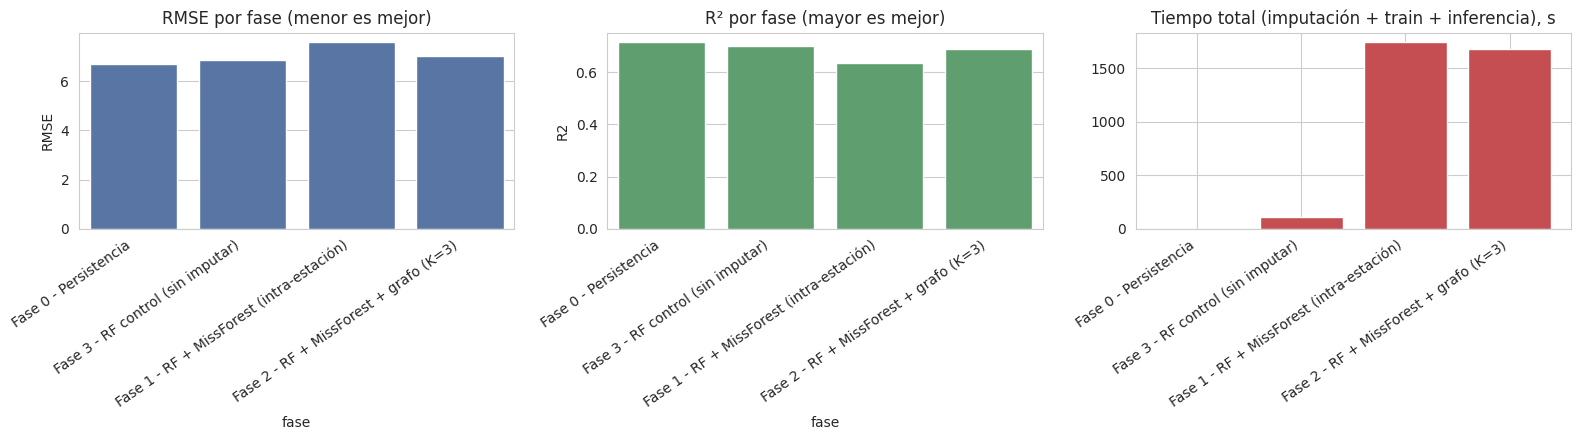

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(data=tabla_resultados, x='fase', y='RMSE', ax=axes[0], color='#4C72B0')
axes[0].set_title('RMSE por fase (menor es mejor)')
axes[0].tick_params(axis='x', rotation=35)
for lbl in axes[0].get_xticklabels():
    lbl.set_ha('right')

sns.barplot(data=tabla_resultados, x='fase', y='R2', ax=axes[1], color='#55A868')
axes[1].set_title('R² por fase (mayor es mejor)')
axes[1].tick_params(axis='x', rotation=35)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha('right')

tiempos_totales = (
    tabla_resultados['tiempo_imputacion_s']
    + tabla_resultados['tiempo_entrenamiento_s']
    + tabla_resultados['tiempo_inferencia_s']
)
axes[2].bar(tabla_resultados['fase'], tiempos_totales, color='#C44E52')
axes[2].set_title('Tiempo total (imputación + train + inferencia), s')
axes[2].tick_params(axis='x', rotation=35)
for lbl in axes[2].get_xticklabels():
    lbl.set_ha('right')

plt.tight_layout()
plt.show()

In [23]:
# Comparación de R² contra los números reportados en el paper (Tabla 1, h1)
# — el R² es la métrica que elegimos como escala-libre para comparar entre datasets.
comparacion_paper = pd.DataFrame({
    'fuente': ['Beijing (paper) - STN', 'Taizhou (paper) - STN'] + tabla_resultados['fase'].tolist(),
    'R2': [0.937, 0.924] + tabla_resultados['R2'].tolist(),
})
comparacion_paper.sort_values('R2', ascending=False)

,fuente,R2
0,Beijing (paper) - STN,0.9370
1,Taizhou (paper) - STN,0.9240
2,Fase 0 - Persistencia,0.7144
3,Fase 3 - RF control (sin imputar),0.7007
5,Fase 2 - RF + MissForest + grafo (K=3),0.6882
4,Fase 1 - RF + MissForest (intra-estación),0.6350


### Cómo leer esta tabla

- Si la **Fase 0 (persistencia)** ya tiene un R² alto (ver pregunta 8 de la guía teórica), cualquier
  fase de RF debe superarla claramente para justificar el modelo — si no la supera por un margen
  amplio, el "aprendizaje" del RF es marginal frente a simplemente copiar la hora anterior.
- Comparar **Fase 3 vs Fase 1**: si el R² sube pero `pct_imputado_train` es alto, hay que sospechar
  del resultado — parte de esa mejora puede venir de que el imputador "inventó" una señal fácil de
  aprender, no de una mejora real en la capacidad predictiva.
- Comparar **Fase 1 vs Fase 2**: si el R² sube y el tiempo de imputación también sube mucho, ahí está
  el trade-off precisión-costo que hay que documentar explícitamente en la conclusión del proyecto.
- La comparación contra Beijing/Taizhou es orientativa (dominios y regímenes de contaminación
  distintos) — sirve para decir "estamos en el mismo orden de magnitud de R²", no para afirmar
  superioridad o inferioridad directa.


---

## Notas y próximos pasos

- Este cuaderno resuelve el pronóstico a **1 hora (h1)**, igual que la Tabla 1 del paper. Para
  replicar las Tablas 2-5 (multi-paso, 6/12/24/48h) hay que extender `construir_features_ventana`
  para generar targets a múltiples horizontes, y decidir entre pronóstico autorregresivo o
  multisalida directa — evitando el atajo de "modelos independientes por intervalo" que señalamos
  como injusto en la pregunta 12 de la guía teórica.
- La validación de hiperparámetros (si se decide ajustar `N_ESTIMATORS_RF` u otros) debe hacerse con
  **ventanas deslizantes dentro del período de train**, nunca con una partición aleatoria del 10%
  (pregunta 7 de la guía teórica) — este cuaderno no la incluye todavía porque usa los hiperparámetros
  por defecto razonables de RF, pero es el siguiente paso antes de pasar a LSTM/STN.
- Cuando se pase a LSTM/STN, el escalador (MinMax o estándar) debe ajustarse únicamente con
  `X_train`/`y_train` de la fase elegida, nunca con el dataset completo (pregunta 5 de la guía teórica).


## Si Colab se sigue quedando sin RAM

Bajá los parámetros de la Sección 1 (`N_ESTIMATORS_IMPUTER`, `MAX_ITER_IMPUTER`,
`N_NEAREST_FEATURES_IMPUTER`) en ese orden, y mirá los mensajes de `reportar_ram()`
que quedaron distribuidos antes/después de cada imputación para ver exactamente
en qué paso se dispara el consumo en tu entorno. Si nada de eso alcanza, la
salida más drástica es cambiar el `estimator=RandomForestRegressor(...)` del
`IterativeImputer` por `BayesianRidge()` (el default de scikit-learn) en las
Fases 1 y 2 — es mucho más liviano, a costa de no capturar relaciones no
lineales entre variables al imputar; si se hace, hay que documentarlo como
cambio de método en la sección de resultados, no solo como ajuste de RAM.


## Si sigue siendo lento

Orden sugerido de ajuste, de mayor a menor impacto en tiempo:

1. **Bajá `MUESTRA_FIT_IMPUTADOR`** (p.ej. de 8000 a 4000-5000). Es la palanca
   más directa: el `fit` del imputador escala aproximadamente lineal con el
   tamaño de esa muestra.
2. **Subí `IMPUTER_N_JOBS`** de 2 a 4 (o más, según núcleos disponibles) —
   ahora que el `fit` corre sobre una muestra chica, paralelizar cuesta menos
   RAM que cuando corría sobre el train completo. Mirá `reportar_ram()` para
   confirmar que no se dispara.
3. **Bajá `MAX_ITER_IMPUTER`** de 4 a 3 — cada iteración de menos es un ciclo
   completo menos por las columnas con NaN.
4. **Usá la caché**: una vez que corriste la imputación una vez en la sesión,
   los `.parquet` en `CACHE_DIR` hacen que las corridas siguientes salten
   directo a entrenar el RF final — útil si estás iterando sobre
   `N_ESTIMATORS_RF` u otros hiperparámetros del modelo de pronóstico. Borrá
   los archivos de `CACHE_DIR` si cambiás algún parámetro del imputador,
   porque la caché no detecta automáticamente ese cambio.


## Diagnóstico si vuelve a ponerse lento

Con el cronometrado separado de `fit()`/`transform()` en las celdas de Fase 1
y Fase 2, mirá cuál de los tres números domina:

- **`fit()` lento** → bajá `MUESTRA_FIT_IMPUTADOR` (la palanca más directa) o
  `N_ESTIMATORS_IMPUTER`.
- **`transform()` lento** (sobre todo el de train, que es el más grande) →
  bajá `MAX_ITER_IMPUTER` — cada iteración de menos es una pasada completa
  menos sobre las ~35.000 filas.
- **Los tres son lentos por igual y `reportar_ram()` muestra >85-90% de uso**
  → el problema ya no es de tiempo puro sino de RAM al límite frenando todo;
  volvé a las palancas de RAM (`N_NEAREST_FEATURES_IMPUTER` más bajo).
- **No subas `IMPUTER_N_JOBS` por encima de 1** salvo que estés en un entorno
  con bastantes cores *y* `MUESTRA_FIT_IMPUTADOR` sea grande (>15.000) — con
  muestras chicas el overhead de paralelizar cientos de fits pequeños suele
  perder contra correrlos en serie.
